In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from sklearn.preprocessing import StandardScaler

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')

STATIONS_EXCEL   = os.path.join(V2_DIR, 'Delhi_list_v2.xlsx')
DATASET_CSV      = os.path.join(V2_DIR, 'EcoTwin_Final_Dataset.csv')
DYNAMIC_ADJ_PATH = os.path.join(V2_DIR, 'dynamic_adj_matrix.npy')

OUT_DIR     = os.path.join(V2_DIR, 'ecotwin_outputs')
DATA_DIR    = os.path.join(OUT_DIR, 'data')
SCALER_DIR  = os.path.join(OUT_DIR, 'scalers')
PLOT_DIR    = os.path.join(OUT_DIR, 'plots')
MODEL_DIR   = os.path.join(OUT_DIR, 'models')
RESULTS_DIR = os.path.join(OUT_DIR, 'results')

for d in [OUT_DIR, DATA_DIR, SCALER_DIR, PLOT_DIR, MODEL_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Output dir: {OUT_DIR}")

Output dir: D:\FYP\Eco-Twin\v2_clean\ecotwin_outputs


In [2]:
df = pd.read_csv(DATASET_CSV, parse_dates=['Timestamp'])
df['Station'] = df['Station'].str.strip()
df = df.sort_values(['Station', 'Timestamp']).reset_index(drop=True)

all_At = np.load(DYNAMIC_ADJ_PATH)

df_stations = pd.read_excel(STATIONS_EXCEL)
df_stations.columns = df_stations.columns.str.strip().str.lower()
df_stations['station'] = df_stations['station'].str.strip()
station_names = df_stations['station'].tolist()
N = len(station_names)

print(f"Rows      : {len(df):,}")
print(f"Stations  : {N}")
print(f"A(t)      : {all_At.shape}")
print(f"Date      : {df['Timestamp'].min()} -> {df['Timestamp'].max()}")

assert all_At.shape[0] == df['Timestamp'].nunique()
assert all_At.shape[1] == N and all_At.shape[2] == N
print("A(t) dimensions match dataset.")

Rows      : 737,077
Stations  : 37
A(t)      : (19921, 37, 37)
Date      : 2024-01-01 00:00:00 -> 2026-04-10 00:00:00
A(t) dimensions match dataset.


In [3]:
df['hour']        = df['Timestamp'].dt.hour
df['day_of_week'] = df['Timestamp'].dt.dayofweek
df['month']       = df['Timestamp'].dt.month
df['is_weekend']  = (df['day_of_week'] >= 5).astype(int)

print(df[['Timestamp','hour','day_of_week','month','is_weekend']].head(6).to_string(index=False))

          Timestamp  hour  day_of_week  month  is_weekend
2024-01-01 00:00:00     0            0      1           0
2024-01-01 01:00:00     1            0      1           0
2024-01-01 02:00:00     2            0      1           0
2024-01-01 03:00:00     3            0      1           0
2024-01-01 04:00:00     4            0      1           0
2024-01-01 05:00:00     5            0      1           0


In [4]:
FEATURE_COLS = ['pm2.5','pm10','no2','so2','co','o3','rh','at',
                'u_wind','v_wind','hour','day_of_week','month','is_weekend']
F = len(FEATURE_COLS)

timestamps = sorted(df['Timestamp'].unique())
T = len(timestamps)
ts_to_idx = {ts: i for i, ts in enumerate(timestamps)}
st_to_idx = {s: i for i, s in enumerate(station_names)}

X_full = np.zeros((T, N, F), dtype=np.float32)

# vectorised build via pivot (much faster than iterrows)
for f_i, col in enumerate(FEATURE_COLS):
    wide = df.pivot_table(index='Timestamp', columns='Station', values=col)
    wide = wide.reindex(columns=station_names)
    X_full[:, :, f_i] = np.nan_to_num(wide.values.astype(np.float32))

Y_full = X_full[:, :, 0].copy()

print(f"X_full : {X_full.shape}  (T={T}, N={N}, F={F})")
print(f"Y_full : {Y_full.shape}")
print(f"Features: {FEATURE_COLS}")

X_full : (19921, 37, 14)  (T=19921, N=37, F=14)
Y_full : (19921, 37)
Features: ['pm2.5', 'pm10', 'no2', 'so2', 'co', 'o3', 'rh', 'at', 'u_wind', 'v_wind', 'hour', 'day_of_week', 'month', 'is_weekend']


In [5]:
ts_arr = np.array(timestamps)
train_end_idx = int(T * 0.70)
val_end_idx   = int(T * 0.85)

TRAIN_END = pd.Timestamp(ts_arr[train_end_idx - 1])
VAL_END   = pd.Timestamp(ts_arr[val_end_idx - 1])

train_mask = ts_arr <= TRAIN_END
val_mask   = (ts_arr > TRAIN_END) & (ts_arr <= VAL_END)
test_mask  = ts_arr > VAL_END

X_train, X_val, X_test = X_full[train_mask], X_full[val_mask], X_full[test_mask]
Y_train, Y_val, Y_test = Y_full[train_mask], Y_full[val_mask], Y_full[test_mask]
At_train, At_val, At_test = all_At[train_mask], all_At[val_mask], all_At[test_mask]

T_tr, T_v, T_te = X_train.shape[0], X_val.shape[0], X_test.shape[0]

print(f"Train ends {TRAIN_END}  ({T_tr:,} hours)")
print(f"Val   ends {VAL_END}    ({T_v:,} hours)")
print(f"Test              ({T_te:,} hours)")
assert T_tr > 0 and T_v > 0 and T_te > 0

Train ends 2025-08-03 23:00:00  (13,944 hours)
Val   ends 2025-12-06 11:00:00    (2,988 hours)
Test              (2,989 hours)


In [6]:
X_tr_2d = X_train.reshape(-1, F)
X_v_2d  = X_val.reshape(-1, F)
X_te_2d = X_test.reshape(-1, F)

scaler = StandardScaler()
scaler.fit(X_tr_2d)

X_train_scaled = scaler.transform(X_tr_2d).reshape(T_tr, N, F).astype(np.float32)
X_val_scaled   = scaler.transform(X_v_2d ).reshape(T_v,  N, F).astype(np.float32)
X_test_scaled  = scaler.transform(X_te_2d).reshape(T_te, N, F).astype(np.float32)

pm25_scaler = StandardScaler()
pm25_scaler.fit(Y_train.reshape(-1, 1))

Y_train_scaled = pm25_scaler.transform(Y_train.reshape(-1,1)).reshape(T_tr, N).astype(np.float32)
Y_val_scaled   = pm25_scaler.transform(Y_val.reshape(-1,1)).reshape(T_v,  N).astype(np.float32)
Y_test_scaled  = pm25_scaler.transform(Y_test.reshape(-1,1)).reshape(T_te, N).astype(np.float32)

with open(os.path.join(SCALER_DIR, 'feature_scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)
with open(os.path.join(SCALER_DIR, 'pm25_scaler.pkl'), 'wb') as f:
    pickle.dump(pm25_scaler, f)

X_chk = X_train_scaled.reshape(-1, F)
print("Per-feature std after scaling (target ~1.0):")
for i, name in enumerate(FEATURE_COLS):
    print(f"  {name:<12} mean={X_chk[:,i].mean():+.3f}  std={X_chk[:,i].std():.3f}")
print(f"\nY_train_scaled  mean={Y_train_scaled.mean():+.3f}  std={Y_train_scaled.std():.3f}")

Per-feature std after scaling (target ~1.0):
  pm2.5        mean=+0.000  std=1.000
  pm10         mean=-0.000  std=1.000
  no2          mean=-0.000  std=1.000
  so2          mean=-0.000  std=1.000
  co           mean=+0.000  std=1.000
  o3           mean=-0.000  std=1.000
  rh           mean=+0.000  std=1.000
  at           mean=+0.000  std=1.000
  u_wind       mean=+0.000  std=1.000
  v_wind       mean=-0.000  std=1.000
  hour         mean=-0.000  std=1.000
  day_of_week  mean=+0.000  std=1.000
  month        mean=+0.000  std=1.000
  is_weekend   mean=-0.000  std=1.000

Y_train_scaled  mean=+0.000  std=1.000


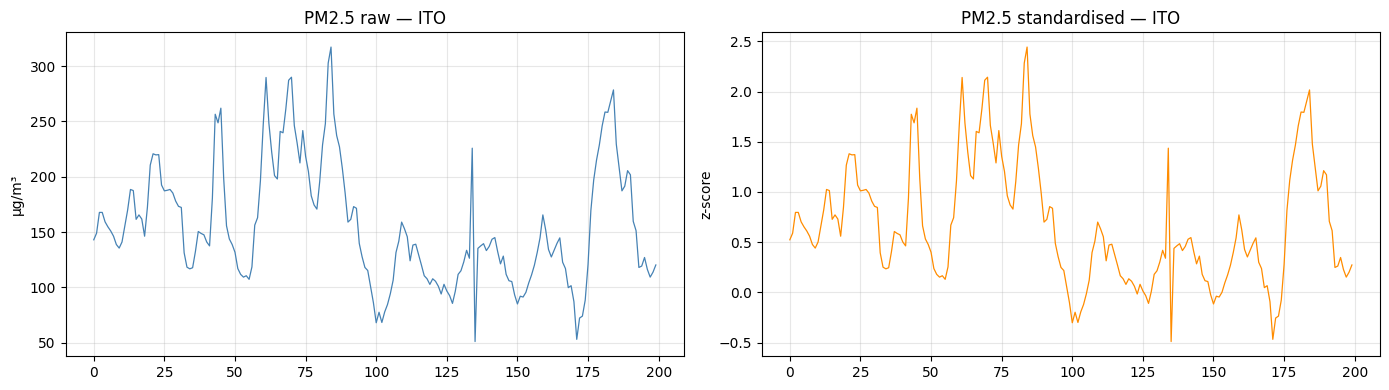

In [7]:
s = 0
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(Y_train[:200, s], color='steelblue', lw=0.9)
axes[0].set_title(f'PM2.5 raw — {station_names[s]}'); axes[0].set_ylabel('µg/m³')
axes[0].grid(True, alpha=0.3)
axes[1].plot(Y_train_scaled[:200, s], color='darkorange', lw=0.9)
axes[1].set_title(f'PM2.5 standardised — {station_names[s]}'); axes[1].set_ylabel('z-score')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'scaling_check.png'), dpi=150, bbox_inches='tight')
plt.show()

In [8]:
INPUT_WINDOW     = 48
FORECAST_HORIZON = 24

def build_windows(Xs, Ys, At, in_len, fc_len):
    T_ = Xs.shape[0]
    n = T_ - (in_len + fc_len) + 1
    if n <= 0:
        raise ValueError(f"Not enough timesteps: {T_}")
    Xw  = np.zeros((n, in_len, Xs.shape[1], Xs.shape[2]), dtype=np.float32)
    Yw  = np.zeros((n, fc_len, Ys.shape[1]), dtype=np.float32)
    Aw  = np.zeros((n, in_len, At.shape[1], At.shape[2]), dtype=np.float32)
    for i in range(n):
        Xw[i] = Xs[i : i+in_len]
        Yw[i] = Ys[i+in_len : i+in_len+fc_len]
        Aw[i] = At[i : i+in_len]
    return Xw, Yw, Aw

X_tr_w, Y_tr_w, At_tr_w    = build_windows(X_train_scaled, Y_train_scaled, At_train, INPUT_WINDOW, FORECAST_HORIZON)
X_val_w, Y_val_w, At_val_w = build_windows(X_val_scaled,   Y_val_scaled,   At_val,   INPUT_WINDOW, FORECAST_HORIZON)
X_te_w, Y_te_w, At_te_w    = build_windows(X_test_scaled,  Y_test_scaled,  At_test,  INPUT_WINDOW, FORECAST_HORIZON)

print(f"Train : X={X_tr_w.shape}  Y={Y_tr_w.shape}  A={At_tr_w.shape}")
print(f"Val   : X={X_val_w.shape}  Y={Y_val_w.shape}  A={At_val_w.shape}")
print(f"Test  : X={X_te_w.shape}  Y={Y_te_w.shape}  A={At_te_w.shape}")

total_gb = sum(a.nbytes for a in [X_tr_w,Y_tr_w,At_tr_w,X_val_w,Y_val_w,At_val_w,X_te_w,Y_te_w,At_te_w]) / 1e9
print(f"\nTotal size: {total_gb:.2f} GB")

Train : X=(13873, 48, 37, 14)  Y=(13873, 24, 37)  A=(13873, 48, 37, 37)
Val   : X=(2917, 48, 37, 14)  Y=(2917, 24, 37)  A=(2917, 48, 37, 37)
Test  : X=(2918, 48, 37, 14)  Y=(2918, 24, 37)  A=(2918, 48, 37, 37)

Total size: 7.21 GB


In [9]:
for name, arr in [
    ('X_train', X_tr_w), ('Y_train', Y_tr_w), ('At_train', At_tr_w),
    ('X_val',   X_val_w),('Y_val',   Y_val_w),('At_val',   At_val_w),
    ('X_test',  X_te_w), ('Y_test',  Y_te_w), ('At_test',  At_te_w),
]:
    np.save(os.path.join(DATA_DIR, f'{name}.npy'), arr)
    print(f"  {name}.npy  {str(arr.shape):<32} {arr.nbytes/1e6:>8.1f} MB")

  X_train.npy  (13873, 48, 37, 14)                1379.8 MB
  Y_train.npy  (13873, 24, 37)                      49.3 MB
  At_train.npy  (13873, 48, 37, 37)                3646.5 MB
  X_val.npy  (2917, 48, 37, 14)                  290.1 MB
  Y_val.npy  (2917, 24, 37)                       10.4 MB
  At_val.npy  (2917, 48, 37, 37)                  766.7 MB
  X_test.npy  (2918, 48, 37, 14)                  290.2 MB
  Y_test.npy  (2918, 24, 37)                       10.4 MB
  At_test.npy  (2918, 48, 37, 37)                  767.0 MB


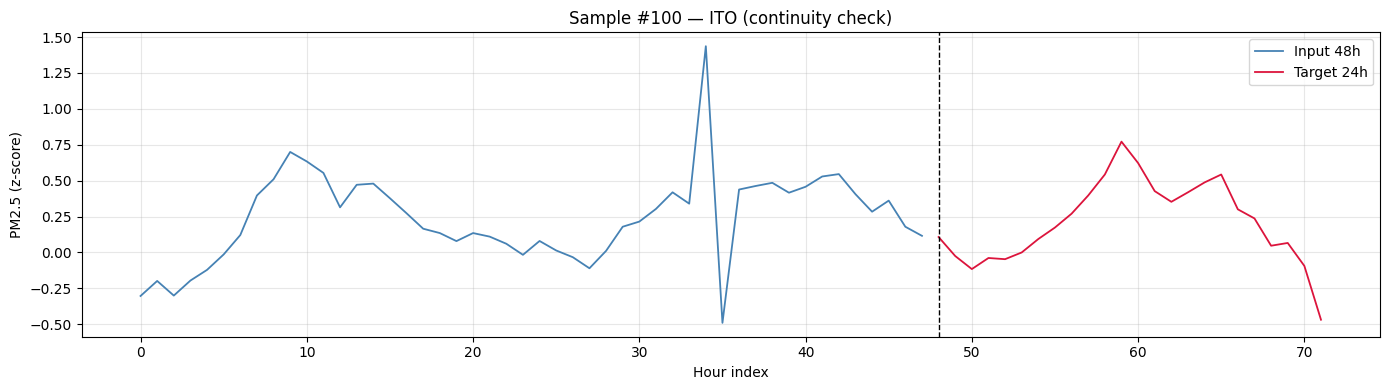

In [10]:
si, sti = 100, 0
inp = X_tr_w[si, :, sti, 0]
tgt = Y_tr_w[si, :, sti]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(range(INPUT_WINDOW), inp, color='steelblue', lw=1.3, label='Input 48h')
ax.plot(range(INPUT_WINDOW, INPUT_WINDOW+FORECAST_HORIZON), tgt, color='crimson', lw=1.3, label='Target 24h')
ax.axvline(INPUT_WINDOW, color='black', ls='--', lw=1)
ax.set_title(f'Sample #{si} — {station_names[sti]} (continuity check)')
ax.set_ylabel('PM2.5 (z-score)'); ax.set_xlabel('Hour index')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'sample_window.png'), dpi=150, bbox_inches='tight')
plt.show()